### Banking Assistant 

In [1]:
import random, time, warnings

import torch
import transformers, trl, peft, datasets
from huggingface_hub.utils import disable_progress_bars

# The one place to change the base model. Any small chat model with a chat template works,
# e.g. "HuggingFaceTB/SmolLM2-360M-Instruct" or "Qwen/Qwen2.5-0.5B-Instruct" (slower to train, better with new phrasings).
BASE_MODEL_ID = "HuggingFaceTB/SmolLM2-135M-Instruct"
SEED = 42

# Use the fastest available device: CUDA GPU, then Apple Silicon (MPS), then CPU.
# Set DEVICE = "cpu" to force CPU training.
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

random.seed(SEED)
transformers.set_seed(SEED)

# Keep the output readable: no progress bars or library chatter
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
datasets.disable_progress_bars()
disable_progress_bars()
warnings.filterwarnings("ignore")

print(f"torch {torch.__version__} | transformers {transformers.__version__} | trl {trl.__version__} | peft {peft.__version__}")
print(f"Base model: {BASE_MODEL_ID} | device: {DEVICE}")

c:\Users\Shyam Gadhiya\OneDrive - Sahana System Limited\Desktop\Banking Customer Support Assistant\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.15.0+cpu | transformers 5.22.1 | trl 1.17.1 | peft 0.21.2
Base model: HuggingFaceTB/SmolLM2-135M-Instruct | device: cpu


In [2]:
import json
import random
import pathlib
import pandas as pd


# Create directory for our fine-tuning data
DATA_DIR = pathlib.Path("bank_finetune_data")
DATA_DIR.mkdir(exist_ok=True)

# --- General Approach to Creating Training Data ---
# 1. Use your domain knowledge base (docs, FAQs, policies, etc.)
# 2. Structure content into clear topics
# 3. Create diverse, well-phrased Q&A pairs

# Example using banking domain
kb_docs = [
    {
        "title": "Account Types",
        "content": {
            "checking": "We offer three types of checking accounts: Basic (no minimum balance), Premium ($2,500 minimum, no fees), and Student (no fees with valid student ID).",
            "savings": "Our savings accounts include Regular (0.5% APY), High-Yield (1.5% APY with $10,000 minimum), and Goal-Based savings with customizable targets.",
            "business": "Business accounts feature unlimited transactions, merchant services integration, and dedicated support. Available in Standard and Premium tiers."
        }
    },
    {
    "title": "Security Protocols",
    "content": {
             "authentication": "We use multi-factor authentication, biometric verification, and device recognition. Login attempts are limited to 3 tries before temporary lockout.",
             "fraud_prevention": "Real-time transaction monitoring, instant fraud alerts, and zero liability protection for unauthorized charges.",
             "data_protection": "End-to-end encryption for all transactions, secure socket layer (SSL) protection, and regular security audits."
         }
     },
     {
         "title": "Digital Banking",
         "content": {
             "mobile_features": "Mobile check deposit, peer-to-peer payments, bill pay, and account aggregation across institutions.",
             "online_services": "Budget tracking, spending analysis, electronic statements, and customizable alerts.",
             "technical_requirements": "Compatible with iOS 13+ and Android 8+. Requires secure internet connection and updated browser versions."
         }
     }
]

def generate_diverse_examples(kb_doc):
    """
    Generate multiple training examples with diverse phrasings and scenarios.
    Following best practices for high-quality training data.
    """
    examples = []
    content = kb_doc["content"]
    
    # Generate examples for each subtopic
    for subtopic, details in content.items():
        # Multiple question variations
        questions = [
            f"Can you explain {subtopic}?",
            f"What should I know about {subtopic}?",
            f"Tell me about your {subtopic}",
            f"How does {subtopic} work?",
            f"I need information regarding {subtopic}",
            f"What are the details of {subtopic}?"
        ]
        
        # Multiple response variations with consistent style
        responses = [
            f"Here's what you need to know about {subtopic}: {details}",
            f"Regarding {subtopic}: {details} Let me know if you need any clarification.",
            f"I'll explain {subtopic}. {details} Is there anything specific you'd like to know more about?",
            f"{details} This information about {subtopic} is current as of today. Please check our website for any updates."
        ]
        
        # Generate combinations with system message variations
        system_messages = [
            "You are a knowledgeable banking assistant focused on providing accurate, compliant information.",
            "You are a helpful financial services expert committed to clear, precise communication.",
            "You are a banking specialist dedicated to providing detailed, accurate responses."
        ]

        for system_msg in system_messages:
            for question in questions:
                for response in responses:
                    examples.append({
                        "messages": [
                            {"role": "system", "content": system_msg},
                            {"role": "user", "content": question},
                            {"role": "assistant", "content": response}
                        ]
                    })
    
    return examples

# Generate comprehensive training dataset
examples = []
for doc in kb_docs:
    examples.extend(generate_diverse_examples(doc))

# Shuffle examples to ensure good distribution
random.shuffle(examples)

print(f"Generated {len(examples)} diverse training examples")

Generated 648 diverse training examples


### Split Training Examples

In [3]:
# Randomly shuffle examples to ensure even distribution between sets
random.shuffle(examples)

# Calculate split point for 80% training, 20% validation
split_index = int(0.8 * len(examples))

# Split examples into training and validation sets
train_examples, validation_examples = examples[:split_index], examples[split_index:]

# Save to JSONL files
train_file = DATA_DIR / "train.jsonl"
validation_file = DATA_DIR / "validation.jsonl"

with open(train_file, "w", encoding="utf-8") as f:
    for example in train_examples:
        f.write(json.dumps(example, ensure_ascii=False) + "\n")

with open(validation_file, "w", encoding="utf-8") as f:
    for example in validation_examples:
        f.write(json.dumps(example, ensure_ascii=False) + "\n")

print(f"✍️ Created {len(train_examples)} training examples and {len(validation_examples)} validation examples")

# Create a DataFrame for easy visualization of example structure
df = pd.DataFrame([
    {
        "system": ex["messages"][0]["content"],
        "user": ex["messages"][1]["content"],
        "assistant": ex["messages"][2]["content"]
    }
    for ex in train_examples[:3]
])
# Display first 3 examples showing system, user, and assistant messages
df

✍️ Created 518 training examples and 130 validation examples


,system,user,assistant
0,You are a helpful financial services expert co...,What are the details of authentication?,"We use multi-factor authentication, biometric ..."
1,You are a helpful financial services expert co...,What are the details of online_services?,Here's what you need to know about online_serv...
2,You are a banking specialist dedicated to prov...,What should I know about fraud_prevention?,Regarding fraud_prevention: Real-time transact...


### Validate Dataset

In [4]:
def validate_jsonl(file_path):
    """Validate that the file is proper JSONL format for fine-tuning."""
    with open(file_path, 'r', encoding='utf-8') as f:
        line_count = 0
        for line in f:
            line_count += 1
            try:
                data = json.loads(line)
                # Check if it has the messages field
                if 'messages' not in data:
                    return False, f"Line {line_count} missing 'messages' field"
                # Check message format
                for msg in data['messages']:
                    if 'role' not in msg or 'content' not in msg:
                        return False, f"Line {line_count} has message missing 'role' or 'content'"
                    if msg['role'] not in ['system', 'user', 'assistant']:
                        return False, f"Line {line_count} has invalid role: {msg['role']}"
            except json.JSONDecodeError:
                return False, f"Line {line_count} is not valid JSON"
    return True, f"Validated {line_count} examples"

# Validate our files
train_valid, train_msg = validate_jsonl(train_file)
val_valid, val_msg = validate_jsonl(validation_file)

print(f"Training file: {'✅' if train_valid else '❌'} {train_msg}")
print(f"Validation file: {'✅' if val_valid else '❌'} {val_msg}")

Training file: ✅ Validated 518 examples
Validation file: ✅ Validated 130 examples


In [5]:
train_questions = {ex["messages"][1]["content"] for ex in train_examples}
train_answers = {ex["messages"][2]["content"] for ex in train_examples}

print(f"Distinct questions in training: {len(train_questions)}, distinct answers: {len(train_answers)}")
q_overlap = sum(ex["messages"][1]["content"] in train_questions for ex in validation_examples)
a_overlap = sum(ex["messages"][2]["content"] in train_answers for ex in validation_examples)
print(f"Validation examples whose question also appears in training: {q_overlap}/{len(validation_examples)}")
print(f"Validation examples whose answer also appears in training:   {a_overlap}/{len(validation_examples)}")

Distinct questions in training: 54, distinct answers: 36
Validation examples whose question also appears in training: 130/130
Validation examples whose answer also appears in training:   130/130


In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID, dtype=torch.float32).to(DEVICE)
print(f"Loaded {BASE_MODEL_ID}: {model.num_parameters() / 1e6:.0f}M parameters\n")

# One training example, rendered with the model's chat template
print(tokenizer.apply_chat_template(train_examples[0]["messages"], tokenize=False))

Loaded HuggingFaceTB/SmolLM2-135M-Instruct: 135M parameters

<|im_start|>system
You are a helpful financial services expert committed to clear, precise communication.<|im_end|>
<|im_start|>user
What are the details of authentication?<|im_end|>
<|im_start|>assistant
We use multi-factor authentication, biometric verification, and device recognition. Login attempts are limited to 3 tries before temporary lockout. This information about authentication is current as of today. Please check our website for any updates.<|im_end|>



### Base Model Before finetuning 

In [7]:
SYSTEM_PROMPT = "You are a knowledgeable banking assistant focused on providing accurate, compliant information."

def ask(model, question, system=SYSTEM_PROMPT, max_new_tokens=100):
    # Generate a reply with greedy decoding so results are repeatable
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    model.eval()
    with torch.no_grad():
        output = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.eos_token_id
        )
    return tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(ask(model, "What savings accounts do you offer?"))

I offer a wide range of savings accounts, including:

Simple Savings Accounts: These are the most basic and widely accepted accounts, offering a fixed interest rate of 2% per month.

Certificates of Deposit (CDs): These are longer-term accounts that pay interest on a fixed daily or weekly basis.

Certificates of Warranty (CWs): These are a type of savings account that provides a guarantee of the account holder's return


### Finetune Using LORA  TRL's SFTTrainer

In [8]:
from datasets import load_dataset, Dataset

raw = load_dataset("json", data_files={"train": str(train_file), "validation": str(validation_file)})

def to_prompt_completion(example):
    # system + user messages become the prompt, the assistant reply becomes the completion
    return {"prompt": example["messages"][:-1], "completion": example["messages"][-1:]}

train_ds = raw["train"].map(to_prompt_completion, remove_columns=["messages"])
val_ds = raw["validation"].map(to_prompt_completion, remove_columns=["messages"])

# Held-out test set: phrasings that never appear in the training data, with the KB facts each answer must contain.
# "reference" answers are written from the knowledge base and are only used to measure loss, never trained on.
test_set = [
    {"question": "What is the minimum balance for a Premium checking account?", "product": "checking",
     "reference": "Premium checking requires a $2,500 minimum balance and has no fees.",
     "facts": ["$2,500"], "phrasing": "new"},
    {"question": "I'm a student. Is there a checking account without fees?", "product": "checking",
     "reference": "Yes. Student checking has no fees with a valid student ID.",
     "facts": ["student ID"], "phrasing": "new"},
    {"question": "What interest rate does the High-Yield savings account pay?", "product": "savings",
     "reference": "High-Yield savings pays 1.5% APY and requires a $10,000 minimum.",
     "facts": ["1.5% APY", "$10,000"], "phrasing": "new"},
    {"question": "What rate does a Regular savings account earn?", "product": "savings",
     "reference": "Regular savings earns 0.5% APY.",
     "facts": ["0.5% APY"], "phrasing": "new"},
    {"question": "Do business accounts limit the number of transactions?", "product": "business",
     "reference": "No. Business accounts include unlimited transactions, merchant services integration and dedicated support.",
     "facts": ["unlimited transactions"], "phrasing": "new"},
    {"question": "Which tiers are available for business accounts?", "product": "business",
     "reference": "Business accounts are available in Standard and Premium tiers.",
     "facts": ["Standard and Premium"], "phrasing": "new"},
    # Two phrasings copied from the training templates, as a control
    {"question": "What should I know about savings?", "product": "savings", "reference": None,
     "facts": ["0.5% APY", "1.5% APY", "$10,000"], "phrasing": "seen"},
     {"question": "Tell me about your checking", "product": "checking", "reference": None,
     "facts": ["$2,500", "student ID"], "phrasing": "seen"},
]

new_phrasings_ds = Dataset.from_list([
    {"prompt": [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": t["question"]}],
     "completion": [{"role": "assistant", "content": t["reference"]}]}
    for t in test_set if t["phrasing"] == "new"
])

print(f"train: {len(train_ds)} | validation: {len(val_ds)} | new-phrasing eval: {len(new_phrasings_ds)}")
print("First training prompt:    ", train_ds[0]["prompt"][1]["content"])
print("First training completion:", train_ds[0]["completion"][0]["content"])

train: 518 | validation: 130 | new-phrasing eval: 6
First training prompt:     What are the details of authentication?
First training completion: We use multi-factor authentication, biometric verification, and device recognition. Login attempts are limited to 3 tries before temporary lockout. This information about authentication is current as of today. Please check our website for any updates.


In [9]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer
from transformers import PrinterCallback

peft_config = LoraConfig(
    r=16,                         # rank of the low-rank update matrices
    lora_alpha=32,                # scaling factor for the update
    lora_dropout=0.05,
    target_modules="all-linear",  # add adapters to every linear layer (attention and MLP)
    task_type="CAUSAL_LM",
)

training_args = SFTConfig(
    output_dir=str(DATA_DIR / "checkpoints"),
    num_train_epochs=3,
    per_device_train_batch_size=8,
    learning_rate=5e-4,             # LoRA tolerates a much higher learning rate than full fine-tuning
    lr_scheduler_type="cosine",
    warmup_steps=5,
    max_length=256,                 # our longest example is about 100 tokens
    logging_steps=5,
    eval_strategy="steps",
    eval_steps=11,                  # evaluate twice per epoch
    eval_on_start=True,             # record the losses before any training, as a baseline
    save_strategy="no",             # we save the adapter explicitly below
    gradient_checkpointing=False,   # not needed for a model this small, and it slows training down
    bf16=False, fp16=False,         # plain float32 works the same on CPU, MPS and CUDA
    use_cpu=(DEVICE == "cpu"),
    report_to="none",
    disable_tqdm=True,
    seed=SEED,
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset={"validation": val_ds, "new_phrasings": new_phrasings_ds},
    processing_class=tokenizer,
    peft_config=peft_config,
)
trainer.remove_callback(PrinterCallback)  # we plot the logs below instead of printing every step

trainer.model.print_trainable_parameters()
start = time.time()
trainer.train()
print(f"Training took {(time.time() - start) / 60:.1f} minutes on {DEVICE}")

trainable params: 4,884,480 || all params: 139,399,488 || trainable%: 3.5039
Training took 53.8 minutes on cpu


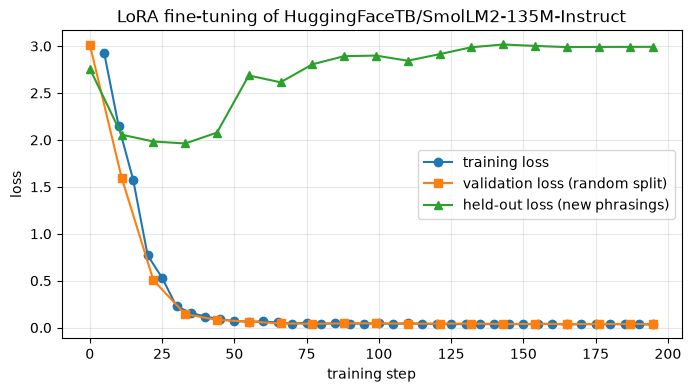

,step,epoch,validation loss,validation token acc,new-phrasing loss,new-phrasing token acc
0,0,0.000,3.016,0.424,2.760,0.425
1,11,0.169,1.599,0.687,2.056,0.566
2,22,0.338,0.505,0.894,1.983,0.585
3,33,0.508,0.144,0.960,1.962,0.642
4,44,0.677,0.083,0.971,2.078,0.585
5,55,0.846,0.064,0.975,2.687,0.604
6,66,1.015,0.045,0.980,2.614,0.623
7,77,1.185,0.041,0.983,2.805,0.632
8,88,1.354,0.046,0.984,2.893,0.632
9,99,1.523,0.046,0.980,2.898,0.623


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
val_log = history.dropna(subset=["eval_validation_loss"])
new_log = history.dropna(subset=["eval_new_phrasings_loss"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(train_log["step"], train_log["loss"], marker="o", label="training loss")
ax.plot(val_log["step"], val_log["eval_validation_loss"], marker="s", label="validation loss (random split)")
ax.plot(new_log["step"], new_log["eval_new_phrasings_loss"], marker="^", label="held-out loss (new phrasings)")
ax.set_xlabel("training step")
ax.set_ylabel("loss")
ax.set_title(f"LoRA fine-tuning of {BASE_MODEL_ID}")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Each evaluation set is logged as its own row; token accuracy = share of reply tokens predicted exactly
summary = val_log[["step", "epoch", "eval_validation_loss", "eval_mean_token_accuracy"]].merge(
    new_log[["step", "eval_new_phrasings_loss", "eval_mean_token_accuracy"]], on="step")
summary.columns = ["step", "epoch", "validation loss", "validation token acc", "new-phrasing loss", "new-phrasing token acc"]
summary.round(3)

### Saved finetuned model

In [11]:
ADAPTER_DIR = DATA_DIR / "banking-lora-adapter"
trainer.save_model(str(ADAPTER_DIR))

adapter_mb = (ADAPTER_DIR / "adapter_model.safetensors").stat().st_size / 1e6
print(f"Saved to {ADAPTER_DIR.name}/: {sorted(f.name for f in ADAPTER_DIR.iterdir())}")
print(f"Adapter weights: {adapter_mb:.1f} MB. The base model weights are not copied; they are loaded from {BASE_MODEL_ID}.")

Saved to banking-lora-adapter/: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
Adapter weights: 19.6 MB. The base model weights are not copied; they are loaded from HuggingFaceTB/SmolLM2-135M-Instruct.


### Integrate finetuned model to Agent

In [2]:
from peft import AutoPeftModelForCausalLM

expert_model = AutoPeftModelForCausalLM.from_pretrained(str(ADAPTER_DIR), dtype=torch.float32)
expert_model = expert_model.merge_and_unload().to(DEVICE)  # fold the LoRA weights into the base weights

def banking_expert(question: str) -> str:
    # The fine-tuned model behind a function the agent can call
    return ask(expert_model, question)

print(banking_expert("What savings accounts do you offer?"))

c:\Users\Shyam Gadhiya\OneDrive - Sahana System Limited\Desktop\Banking Customer Support Assistant\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'ADAPTER_DIR' is not defined

### Adding Query Router and guardrails 

In [13]:
import re
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# Tools: deterministic code that a real system would back with authenticated APIs
def account_lookup(account_id: str) -> str:
    # Look up account information by account ID (requires authentication)
    return f"Account {account_id} information is available after authentication."

def transfer_payment(destination_account: str, amount: float) -> str:
    # Prepare a transfer; the customer still has to authenticate to confirm it
    return f"Transfer of ${amount:,.2f} to account {destination_account} is prepared. Please authenticate to confirm it."

# What the fine-tuned model was trained on. Questions outside these topics are handed off.
KB_TOPICS = ("checking", "savings", "business", "account type", "apy", "interest", "minimum balance", "student")

class AgentState(TypedDict):
    query: str
    route: str
    answer: str

def route_query(state: AgentState) -> dict:
    q = state["query"].lower()
    account = re.search(r"\b\d{6,}\b", q)
    if re.search(r"\b(transfer|send|wire|pay)\b", q) and re.search(r"\$\s?\d", q) and account:
        route = "transfer"
    elif account or re.search(r"\bmy (balance|account)\b", q):
        route = "lookup"
    elif any(topic in q for topic in KB_TOPICS):
        route = "knowledge"
    else:
        route = "handoff"
    return {"route": route}
def transfer_node(state: AgentState) -> dict:
    amount = float(re.search(r"\$\s?([\d,]+(?:\.\d+)?)", state["query"]).group(1).replace(",", ""))
    account = re.search(r"\b\d{6,}\b", state["query"]).group(0)
    return {"answer": transfer_payment(account, amount)}

def lookup_node(state: AgentState) -> dict:
    account = re.search(r"\b\d{6,}\b", state["query"])
    return {"answer": account_lookup(account.group(0) if account else "on file")}

def knowledge_node(state: AgentState) -> dict:
    return {"answer": banking_expert(state["query"])}

def handoff_node(state: AgentState) -> dict:
    return {"answer": "I can answer questions about our checking, savings and business accounts. "
                      "For anything else, I'll connect you with a member of our support team."}

builder = StateGraph(AgentState)
builder.add_node("router", route_query)
builder.add_node("transfer", transfer_node)
builder.add_node("lookup", lookup_node)
builder.add_node("knowledge", knowledge_node)
builder.add_node("handoff", handoff_node)
builder.add_edge(START, "router")
builder.add_conditional_edges("router", lambda state: state["route"], ["transfer", "lookup", "knowledge", "handoff"])
for node in ["transfer", "lookup", "knowledge", "handoff"]:
    builder.add_edge(node, END)
agent = builder.compile()

test_queries = [
    "What account types do you offer?",
    "Is there a checking account for students?",
    "What are the fees for wire transfers?",
    "I need information about overdraft protection",
    "I want to transfer $50,000 to account 1234567",
    "What's the balance on account 98765432?",
]

for query in test_queries:
    result = agent.invoke({"query": query})
    print(f"Query: {query}\nRoute: {result['route']}\nResponse: {result['answer']}\n")

Query: What account types do you offer?
Route: knowledge
Response: I'll explain account types. Budget-Based: Includes three types: Basic (no minimum balance), Premium ($2,500 minimum, no fees), and Student (no fees with valid student ID). Is there anything specific you'd like to know more about?

Query: Is there a checking account for students?
Route: knowledge
Response: Here's what you need to know about checking accounts for students: We offer three types of checking accounts: Basic (no minimum balance), Premium ($2,500 minimum, no fees), and Student (no fees with valid student ID).

Query: What are the fees for wire transfers?
Route: handoff
Response: I can answer questions about our checking, savings and business accounts. For anything else, I'll connect you with a member of our support team.

Query: I need information about overdraft protection
Route: handoff
Response: I can answer questions about our checking, savings and business accounts. For anything else, I'll connect you wit

In [1]:
query1 = " I need information about overdraft protection"
result = agent.invoke({"query": query1})
print(f"Query: {query1}\nRoute: {result['route']}\nResponse: {result['answer']}\n")

NameError: name 'agent' is not defined

### Model Comparision & Evaluation


In [16]:
peft_model = trainer.model
kb_text = " ".join(f"{topic.capitalize()}: {details}" for topic, details in kb_docs[0]["content"].items())
KB_PROMPT = f"{SYSTEM_PROMPT} Answer using only these facts. {kb_text}"

# The distinctive facts of each product in the knowledge base
product_facts = {
    "checking": ["$2,500", "student ID"],
    "savings": ["0.5% APY", "1.5% APY", "$10,000"],
    "business": ["unlimited transactions", "merchant services", "Standard and Premium"],
}

def facts_found(answer, facts):
    normalize = lambda s: s.lower().replace(",", "")
    return sum(normalize(fact) in normalize(answer) for fact in facts)

def other_product_facts(answer, product):
    # Facts that belong to a different product than the one the customer asked about
    return [f for p, facts in product_facts.items() if p != product for f in facts if facts_found(answer, [f])]

setups = ["base", "base + facts in prompt", "fine-tuned"]
rows = []
for item in test_set:
    with peft_model.disable_adapter():  # the original model, without the LoRA adapter
        answers = {"base": ask(peft_model, item["question"]),
                   "base + facts in prompt": ask(peft_model, item["question"], system=KB_PROMPT)}
    answers["fine-tuned"] = ask(peft_model, item["question"])
    for setup, answer in answers.items():
        rows.append({"question": item["question"], "phrasing": item["phrasing"], "setup": setup, "answer": answer,
                     "found": facts_found(answer, item["facts"]), "expected": len(item["facts"]),
                     "mixed_up": other_product_facts(answer, item["product"])})
results = pd.DataFrame(rows)

summary = []
for setup in setups:
    r = results[results["setup"] == setup]
    new, seen = r[r["phrasing"] == "new"], r[r["phrasing"] == "seen"]
    summary.append({
        "setup": setup,
        "KB facts found, new phrasings (6 questions)": f"{new['found'].sum()}/{new['expected'].sum()}",
        "KB facts found, seen phrasings (2 questions)": f"{seen['found'].sum()}/{seen['expected'].sum()}",
        "answers quoting another product's facts": f"{(r['mixed_up'].str.len() > 0).sum()}/{len(r)}",
    })
pd.DataFrame(summary).set_index("setup")

,"KB facts found, new phrasings (6 questions)","KB facts found, seen phrasings (2 questions)",answers quoting another product's facts
setup,,,
base,0/7,0/5,0/8
base + facts in prompt,4/7,0/5,3/8
fine-tuned,6/7,5/5,1/8
